# DATA MINING, MODELING AND ANALYTICS – ASSIGNMENT 1
**Project 2: Concrete Compressive Strength Regression**
**Name:** Nabyonga Theresa
**Registration Number:** S25m19/040
**Programme:** Master of Science in Data Science and Analystics 

# PROJECT 2: CONCRETE COMPRESSIVE STRENGTH REGRESSION
## 1. Introduction
Concrete compressive strength is an important measure of concrete quality and is influenced by its mixture ingredients and curing age. This project aims to use machine learning to predict concrete strength based on these factors.

## 1.1 Problem Formulation
The problem is formulated as a supervised regression task because compressive strength is a continuous numerical value measured in MPa. Linear and nonlinear regression models will be compared against a mean-prediction baseline using MAE, RMSE and R². Residual analysis will also be used to examine prediction errors and identify where the models perform poorly.

In [1]:
# Importing necessary libraries 
# Data manipulation
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Data splitting and preprocessing
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Regression models
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Additional tools
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Loading the concrete compressive strength dataset
df = pd.read_csv("Concrete_Data.csv")

# Display the first five records
df.head()

,Cement (kg in a m^3 mixture),Blast Furnace Slag (kg in a m^3 mixture),Fly Ash (kg in a m^3 mixture),Water (kg in a m^3 mixture),Superplasticizer (kg in a m^3 mixture),Coarse Aggregate (kg in a m^3 mixture),Fine Aggregate (kg in a m^3 mixture),Age (day),"Concrete compressive strength (MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [3]:
print("Dataset dimensions:", df.shape)

Dataset dimensions: (1030, 9)


In [4]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['Cement (kg in a m^3 mixture)', 'Blast Furnace Slag (kg in a m^3 mixture)', 'Fly Ash (kg in a m^3 mixture)', 'Water (kg in a m^3 mixture)', 'Superplasticizer (kg in a m^3 mixture)', 'Coarse Aggregate (kg in a m^3 mixture)', 'Fine Aggregate (kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength (MPa, megapascals) ']


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   Cement (kg in a m^3 mixture)                       1030 non-null   float64
 1   Blast Furnace Slag (kg in a m^3 mixture)           1030 non-null   float64
 2   Fly Ash (kg in a m^3 mixture)                      1030 non-null   float64
 3   Water (kg in a m^3 mixture)                        1030 non-null   float64
 4   Superplasticizer (kg in a m^3 mixture)             1030 non-null   float64
 5   Coarse Aggregate (kg in a m^3 mixture)             1030 non-null   float64
 6   Fine Aggregate (kg in a m^3 mixture)               1030 non-null   float64
 7   Age (day)                                          1030 non-null   int64  
 8   Concrete compressive strength (MPa, megapascals)   1030 non-null   float64
dtypes: float64(8), int64

In [6]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Cement (kg in a m^3 mixture)                         0
Blast Furnace Slag (kg in a m^3 mixture)             0
Fly Ash (kg in a m^3 mixture)                        0
Water (kg in a m^3 mixture)                          0
Superplasticizer (kg in a m^3 mixture)               0
Coarse Aggregate (kg in a m^3 mixture)               0
Fine Aggregate (kg in a m^3 mixture)                 0
Age (day)                                            0
Concrete compressive strength (MPa, megapascals)     0
dtype: int64


In [7]:
# Summary statistics
df.describe().round(2)

,Cement (kg in a m^3 mixture),Blast Furnace Slag (kg in a m^3 mixture),Fly Ash (kg in a m^3 mixture),Water (kg in a m^3 mixture),Superplasticizer (kg in a m^3 mixture),Coarse Aggregate (kg in a m^3 mixture),Fine Aggregate (kg in a m^3 mixture),Age (day),"Concrete compressive strength (MPa, megapascals)"
count,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00,1030.00
mean,281.17,73.90,54.19,181.57,6.20,972.92,773.58,45.66,35.82
std,104.51,86.28,64.00,21.36,5.97,77.75,80.18,63.17,16.71
min,102.00,0.00,0.00,121.75,0.00,801.00,594.00,1.00,2.33
25%,192.38,0.00,0.00,164.90,0.00,932.00,730.95,7.00,23.71
50%,272.90,22.00,0.00,185.00,6.35,968.00,779.51,28.00,34.44
75%,350.00,142.95,118.27,192.00,10.16,1029.40,824.00,56.00,46.14
max,540.00,359.40,200.10,247.00,32.20,1145.00,992.60,365.00,82.60


In [8]:
print("Number of duplicate records:", df.duplicated().sum())

Number of duplicate records: 25


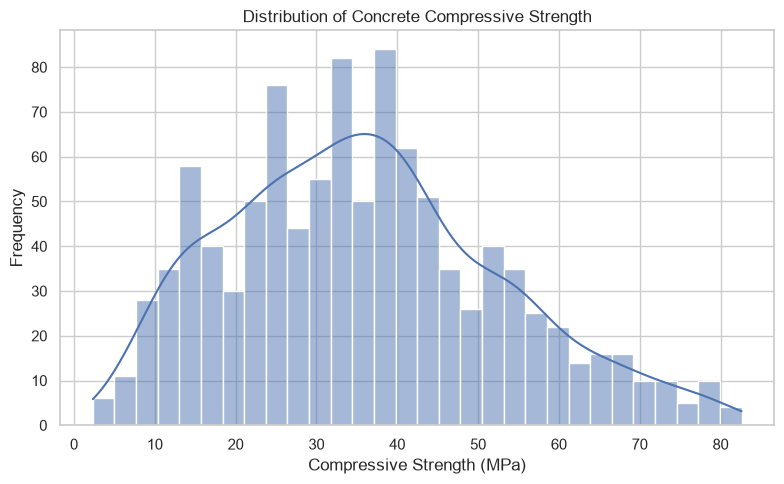

In [10]:
# Plot the distribution of concrete compressive strength
target = 'Concrete compressive strength (MPa, megapascals) '

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x=target,
    bins=30,
    kde=True
)

plt.title("Distribution of Concrete Compressive Strength")
plt.xlabel("Compressive Strength (MPa)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## 2. Initial Data Exploration

The dataset contains 1,030 observations and nine numerical variables, comprising eight input features and concrete compressive strength as the target variable. No missing values were found, although 25 duplicate records were identified and will be investigated.

Concrete strength has a mean of 35.82 MPa, with values ranging from 2.33 to 82.60 MPa. This indicates considerable variation in strength across the different concrete mixtures. The dataset is suitable for exploring relationships between mixture composition, curing age and compressive strength.

In [11]:
# Examining the exact duplicate records
duplicates = df[df.duplicated(keep=False)].sort_values(
    by=list(df.columns)
)

print("Total rows involved in duplicate groups:", len(duplicates))

duplicates.head(15)

Total rows involved in duplicate groups: 36


,Cement (kg in a m^3 mixture),Blast Furnace Slag (kg in a m^3 mixture),Fly Ash (kg in a m^3 mixture),Water (kg in a m^3 mixture),Superplasticizer (kg in a m^3 mixture),Coarse Aggregate (kg in a m^3 mixture),Fine Aggregate (kg in a m^3 mixture),Age (day),"Concrete compressive strength (MPa, megapascals)"
801,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
809,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
106,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
129,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.298713


In [12]:
# Compare original and unique record counts
print("Original records:", len(df))
print("Unique records:", df.drop_duplicates().shape[0])

Original records: 1030
Unique records: 1005


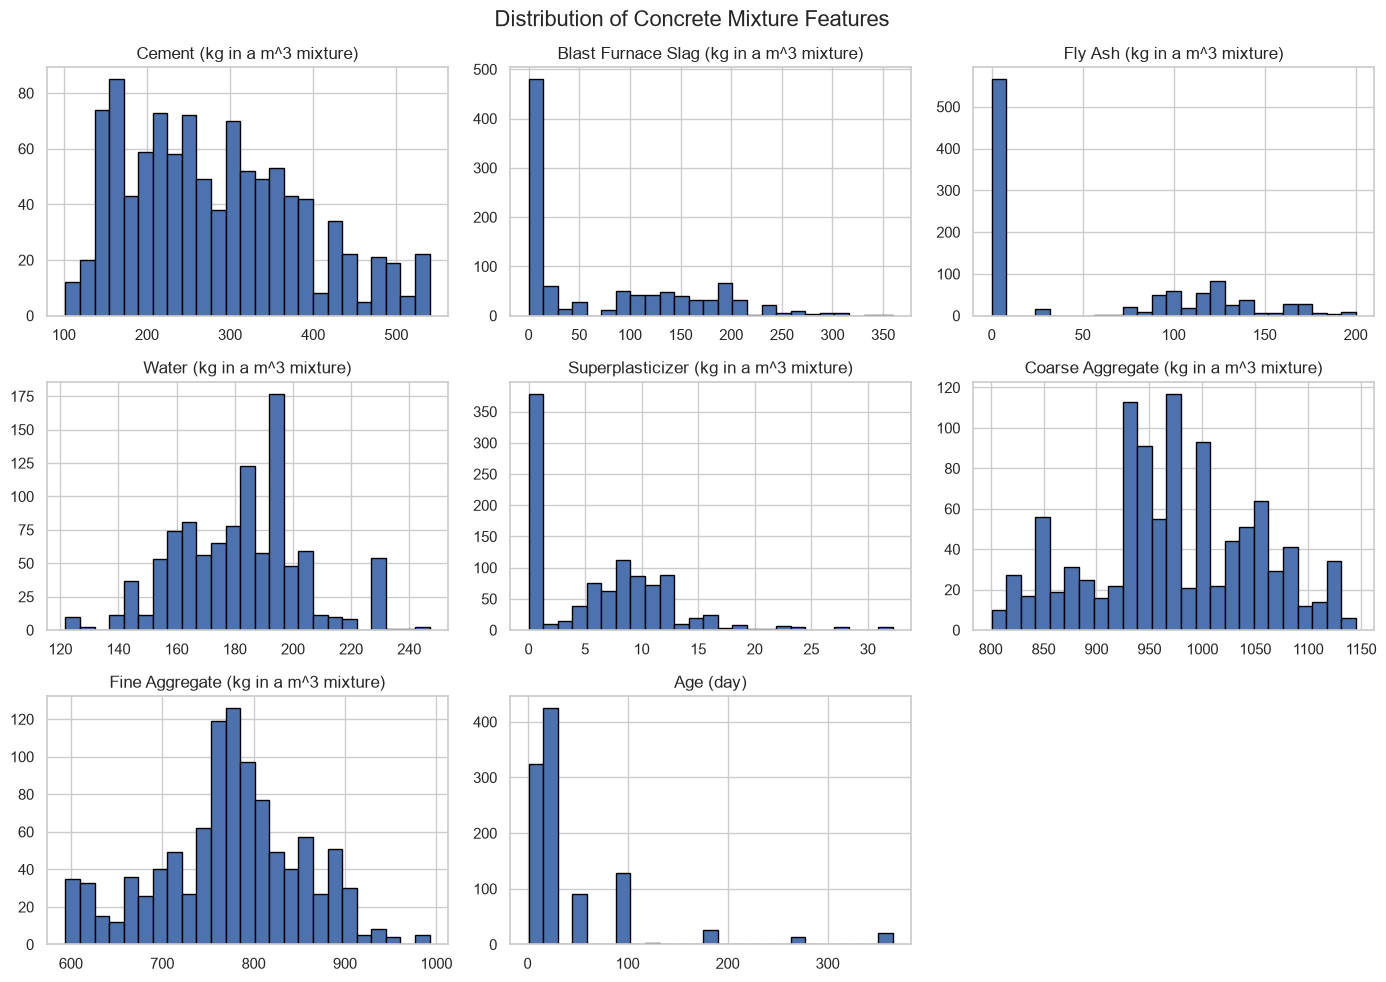

In [13]:
# Plot distributions of input features
features = df.columns[:-1]

df[features].hist(
    figsize=(14, 10),
    bins=25,
    edgecolor='black'
)

plt.suptitle("Distribution of Concrete Mixture Features", fontsize=16)
plt.tight_layout()
plt.show()

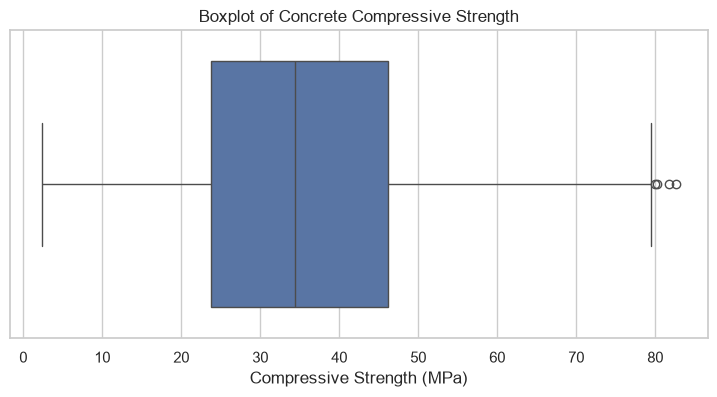

In [14]:
plt.figure(figsize=(9, 4))

sns.boxplot(
    x=df['Concrete compressive strength (MPa, megapascals) ']
)

plt.title("Boxplot of Concrete Compressive Strength")
plt.xlabel("Compressive Strength (MPa)")
plt.show()

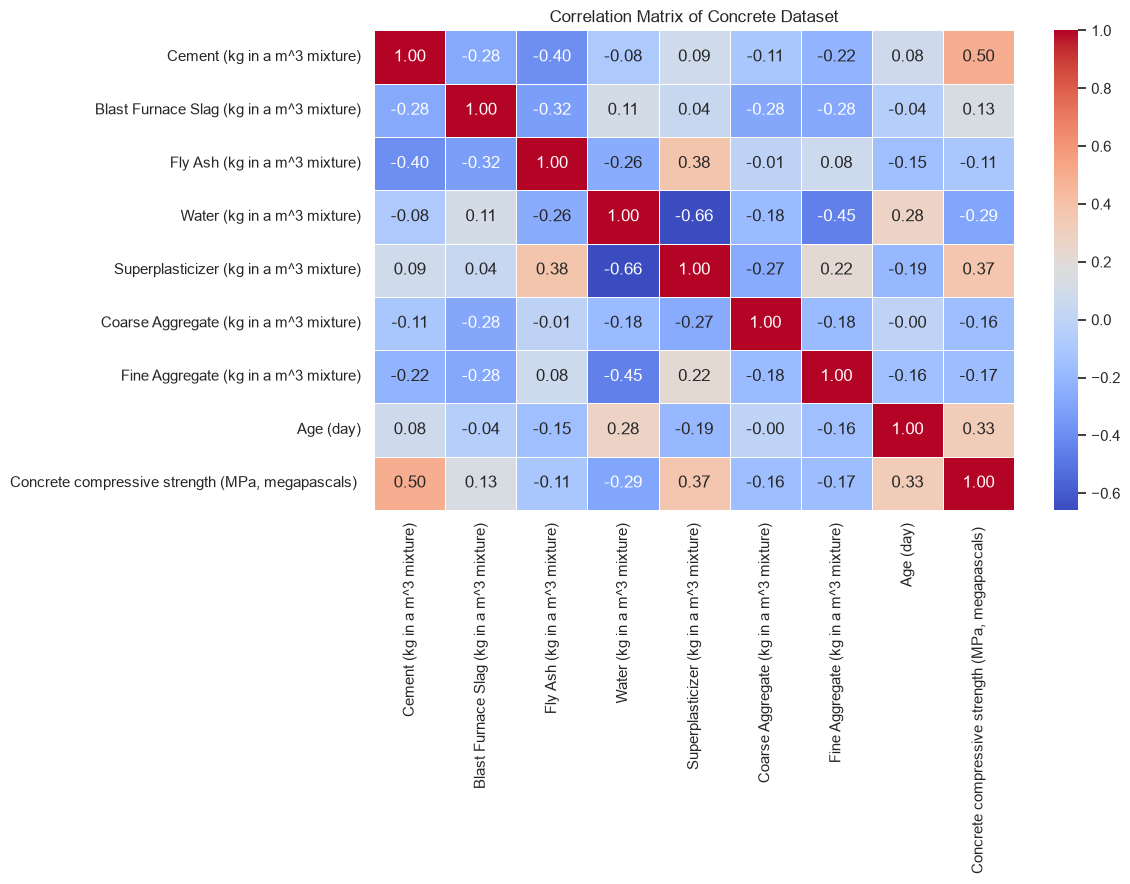

In [15]:
# Calculating correlations between numerical variables
correlation_matrix = df.corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Matrix of Concrete Dataset")
plt.tight_layout()
plt.show()

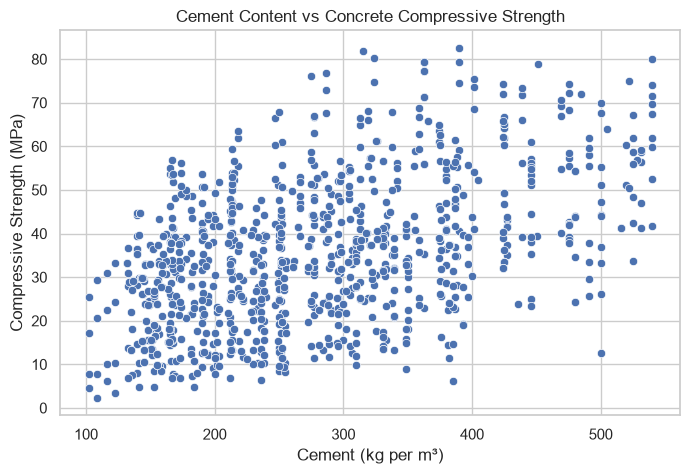

In [16]:
target = 'Concrete compressive strength (MPa, megapascals) '

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Cement (kg in a m^3 mixture)',
    y=target
)

plt.title("Cement Content vs Concrete Compressive Strength")
plt.xlabel("Cement (kg per m³)")
plt.ylabel("Compressive Strength (MPa)")
plt.show()

In [17]:
# Make a copy of the original dataset
data = df.copy()

# Remove exact duplicate records
data = data.drop_duplicates().reset_index(drop=True)

print("Original dataset size:", df.shape)
print("Dataset after removing duplicates:", data.shape)
print("Remaining duplicates:", data.duplicated().sum())

Original dataset size: (1030, 9)
Dataset after removing duplicates: (1005, 9)
Remaining duplicates: 0


In [18]:
data.columns = [
    'cement',
    'slag',
    'fly_ash',
    'water',
    'superplasticizer',
    'coarse_aggregate',
    'fine_aggregate',
    'age',
    'strength'
]

data.head()

,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [19]:
# Separating input features and target
X = data.drop(columns=['strength'])
y = data['strength']

print("Input features:", X.shape)
print("Target variable:", y.shape)

Input features: (1005, 8)
Target variable: (1005,)


In [20]:
# Spliting the dataset
# 80% of the data for training and 20% for testing.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (804, 8)
Testing set: (201, 8)


## 3. Data Preparation

No missing values were found in the dataset. However, 25 duplicate records were identified and removed, reducing the dataset from 1,030 to 1,005 observations. Column names were simplified, and the eight input features were separated from the target variable (compressive strength).

The data was split into 80% training and 20% testing sets using a fixed random state to ensure reproducibility. No imputation or feature scaling was necessary.

In [21]:
# Creating the mean-prediction baseline
baseline_model = DummyRegressor(strategy='mean')

# Train the baseline
baseline_model.fit(X_train, y_train)

# Generate predictions
baseline_predictions = baseline_model.predict(X_test)

# Evaluate baseline performance
baseline_mae = mean_absolute_error(y_test, baseline_predictions)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(y_test, baseline_predictions)

print("MEAN-PREDICTION BASELINE RESULTS")
print("--------------------------------")
print("MAE:", round(baseline_mae, 4))
print("RMSE:", round(baseline_rmse, 4))
print("R-squared:", round(baseline_r2, 4))

MEAN-PREDICTION BASELINE RESULTS
--------------------------------
MAE: 13.9723
RMSE: 17.2965
R-squared: -0.0028


## 4. Mean-prediction Baseline explanation. 
The mean-prediction baseline achieved an MAE of 13.9723 MPa, an RMSE of 17.2965 MPa and an R-squared value of -0.0028. The results indicate that predicting the average compressive strength for every observation provides limited predictive accuracy.

The slightly negative R-squared value shows that the baseline performs marginally worse than predicting the actual mean strength of the test set. These results establish a reference point against which the performance of the linear and nonlinear regression models will be compared.

In [22]:
# Define the regression models
models = {
    'Linear Regression': LinearRegression(),

    'Random Forest': RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),

    'HistGradientBoosting': HistGradientBoostingRegressor(
        random_state=42
    )
}

# Store model results and predictions
results = []
predictions = {}

for name, model in models.items():

    # Train the model
    model.fit(X_train, y_train)

    # Predict concrete strength
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'R-squared': r2
    })

    predictions[name] = y_pred

# Display comparison
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='RMSE',
    ascending=True
)

print("REGRESSION MODEL COMPARISON")
display(results_df.round(4))

REGRESSION MODEL COMPARISON


,Model,MAE,RMSE,R-squared
2,HistGradientBoosting,3.0369,4.5496,0.9306
1,Random Forest,3.4834,5.1391,0.9115
0,Linear Regression,8.8960,11.1922,0.5801


## 5. Regression Model Comparison

Three regression models were compared using MAE, RMSE and R-squared. HistGradientBoosting performed best, achieving an MAE of 3.0369 MPa, RMSE of 4.5496 MPa and R-squared of 0.9306. Random Forest followed with an R-squared of 0.9115, while Linear Regression performed less effectively with an R-squared of 0.5801.

All three models outperformed the mean-prediction baseline. The results suggest that nonlinear models capture the relationships between concrete mixture characteristics, curing age and compressive strength better than Linear Regression. HistGradientBoosting was therefore selected for further analysis.

In [23]:
# Getting predictions from the best-performing model
best_predictions = predictions['HistGradientBoosting']

# Create a dataframe for residual analysis
residuals_df = pd.DataFrame({
    'Actual Strength': y_test.values,
    'Predicted Strength': best_predictions,
    'Residual': y_test.values - best_predictions
})

# Calculate absolute prediction errors
residuals_df['Absolute Error'] = abs(residuals_df['Residual'])

# Display the five weakest predictions
weakest_predictions = residuals_df.sort_values(
    by='Absolute Error',
    ascending=False
).head(10)

print("TEN WEAKEST PREDICTIONS")
display(weakest_predictions.round(3))

TEN WEAKEST PREDICTIONS


,Actual Strength,Predicted Strength,Residual,Absolute Error
188,81.751,54.479,27.272,27.272
56,76.235,59.057,17.178,17.178
11,49.249,32.428,16.821,16.821
48,74.987,61.790,13.197,13.197
175,45.898,34.668,11.231,11.231
173,7.315,17.878,-10.563,10.563
97,63.142,52.854,10.288,10.288
130,6.267,16.519,-10.252,10.252
116,59.764,49.909,9.854,9.854
187,80.200,70.358,9.842,9.842


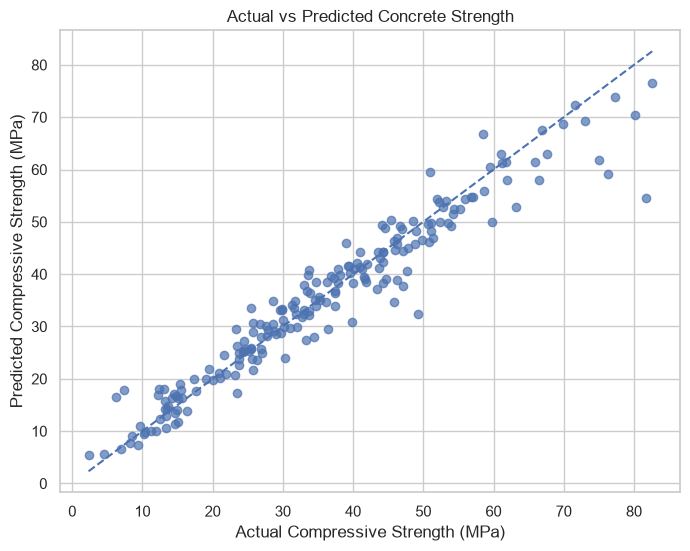

In [24]:
# Actual versus predicted values
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Compressive Strength (MPa)")
plt.ylabel("Predicted Compressive Strength (MPa)")
plt.title("Actual vs Predicted Concrete Strength")

plt.show()

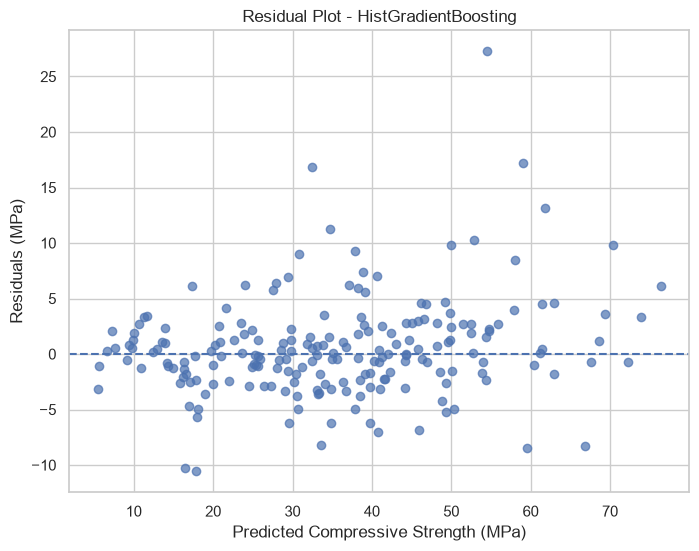

In [25]:
# Residual plot
residuals = y_test.values - best_predictions

plt.figure(figsize=(8, 6))

plt.scatter(
    best_predictions,
    residuals,
    alpha=0.7
)

plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted Compressive Strength (MPa)")
plt.ylabel("Residuals (MPa)")
plt.title("Residual Plot - HistGradientBoosting")

plt.show()

## 6. Residual Analysis

Residual analysis was conducted using HistGradientBoosting, the best-performing model. The ten largest prediction errors were examined. The largest error was 27.272 MPa, where actual strength was 81.751 MPa but predicted strength was 54.479 MPa. The model also overestimated two samples with very low actual strengths.

These findings show that although the model performs well overall, it struggles with some high-strength and very low-strength samples. Mixture composition and curing age will be examined to explore possible reasons for these errors.

In [26]:
# Getting the positions of the ten weakest predictions
weakest_indices = weakest_predictions.index

# Retrieve their original input features
weakest_features = X_test.reset_index(drop=True).iloc[weakest_indices].copy()

# Combine input features with actual and predicted strength
weakest_details = weakest_features.copy()

weakest_details['Actual Strength'] = (
    y_test.reset_index(drop=True).iloc[weakest_indices].values
)

weakest_details['Predicted Strength'] = (
    best_predictions[weakest_indices]
)

weakest_details['Absolute Error'] = (
    weakest_predictions['Absolute Error'].values
)

print("FEATURES OF THE TEN WEAKEST PREDICTIONS")

display(weakest_details.round(3))

FEATURES OF THE TEN WEAKEST PREDICTIONS


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,Actual Strength,Predicted Strength,Absolute Error
188,315.00,137.00,0.00,145.00,5.90,1130.0,745.00,28,81.751,54.479,27.272
56,275.00,180.00,120.00,162.00,10.35,830.0,765.00,28,76.235,59.057,17.178
11,200.00,200.00,0.00,190.00,0.00,1145.0,660.00,28,49.249,32.428,16.821
48,522.00,0.00,0.00,146.00,0.00,896.0,896.00,28,74.987,61.790,13.197
175,387.00,20.00,94.00,157.00,13.93,938.0,845.00,7,45.898,34.668,11.231
173,182.04,45.21,121.97,170.21,8.19,1059.4,780.65,3,7.315,17.878,10.563
97,277.19,97.82,24.46,160.70,11.19,1061.7,782.46,28,63.142,52.854,10.288
130,385.00,0.00,0.00,186.00,0.00,966.0,763.00,1,6.267,16.519,10.252
116,540.00,0.00,0.00,173.00,0.00,1125.0,613.00,14,59.764,49.909,9.854
187,323.70,282.80,0.00,183.80,10.30,942.7,659.90,56,80.200,70.358,9.842


### 6.1 Examination of the Weakest Predictions

The model underestimated several high-strength samples, with the largest error being 27.272 MPa. It also overestimated two samples with very low actual strengths of 7.315 MPa and 6.267 MPa.

These errors occurred across different curing ages, suggesting that mixture composition and interactions between ingredients may also influence prediction accuracy. Overall, the model performed well but was less accurate for some samples at the extremes of the strength range.

## 7. Association Between Cement Content and Concrete Strength

Although cement content may show a positive association with concrete compressive strength, this does not prove that increasing cement alone will always increase strength.

Concrete strength depends on several interacting factors, including water content, curing age, aggregates, slag, fly ash and superplasticizer. These variables may influence one another, making it difficult to isolate the effect of cement using observational data.

Therefore, the model identifies predictive relationships rather than proving cause-and-effect relationships. Controlled experiments would be needed to establish how changing cement content affects concrete strength while accounting for other mixture factors.

In [28]:
# Evaluating the best model using 5-fold cross-validation
best_model = HistGradientBoostingRegressor(random_state=42)

cv_results = cross_validate(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring={
        'MAE': 'neg_mean_absolute_error',
        'RMSE': 'neg_root_mean_squared_error',
        'R2': 'r2'
    }
)

print("5-FOLD CROSS-VALIDATION RESULTS")
print("--------------------------------")
print("Mean MAE:", round(-cv_results['test_MAE'].mean(), 4))
print("Mean RMSE:", round(-cv_results['test_RMSE'].mean(), 4))
print("Mean R-squared:", round(cv_results['test_R2'].mean(), 4))

5-FOLD CROSS-VALIDATION RESULTS
--------------------------------
Mean MAE: 3.3443
Mean RMSE: 4.823
Mean R-squared: 0.9084


## 8. Model Robustness and Cross-Validation

Five-fold cross-validation was performed on the training data to assess the consistency of HistGradientBoosting. The model achieved a mean MAE of 3.3443 MPa, RMSE of 4.8230 MPa and R-squared of 0.9084.

These results were close to the test-set performance, suggesting that the model generalises reasonably well across different data subsets. This provides additional confidence in its predictive performance.

## 9. Conclusion

This project compared three regression models for predicting concrete compressive strength using mixture composition and curing age. HistGradientBoosting achieved the best performance, with an MAE of 3.0369 MPa, RMSE of 4.5496 MPa and R-squared of 0.9306. Cross-validation also confirmed its consistent performance.

Residual analysis showed that the model performed well overall but struggled with some very high-strength and low-strength samples.

The relationship between cement content and strength represents predictive association, not proof of causation, since concrete strength depends on several interacting ingredients and curing conditions.

Overall, HistGradientBoosting was the most suitable model among those evaluated.